## Output Comparison
Compare output across sites

In [1]:
# Run settings
sites = ['Cumbres Trestle','Cumbres Trestle']
namelists = ['ghelaps','ghelaps']
forcing_strs = ['01011010','01012010']
forcing_versions = ['0.10.1','0.11.1']
versions = ['0008','0011']
isAlpine = True

In [2]:
# Load environmental variables if on Alpine, otherwise they should be stored
import os

# Configure environmental variables
if isAlpine:
    os.environ['OUTPUT_PATH'] = r'/pl/active/snotelmodelling/model_data/output/' #Alpine
    os.environ['SNOTEL_PATH'] = r'/pl/active/snotelmodelling/snotel/'
    os.environ['FORCING_PATH'] = r'/pl/active/snotelmodelling/model_data/input/forcing/'

In [3]:
%matplotlib ipympl
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
from model_datasets.forcing import LM4Forcing
from model_datasets.output import LM4ModelOutput 
from buildforcing.datasets import PNNLSnotel

Load datasets

In [4]:
models = {}
forcings = {}
names = []
for (site,namelist,forcing_str,version,forcing_version) in zip(sites,namelists,forcing_strs,versions,forcing_versions):
    name = '_'.join((site.lower().replace(' ',''),forcing_str,namelist,version))
    names.append(name)
    models[name] = LM4ModelOutput(site=site, forcing_string=forcing_str, namelist=namelist, version=version, spinup=False)
    forcings[name] = LM4Forcing(site=site, forcing_string=forcing_str, version=forcing_version, spinup=False)

In [5]:
forcings

{'cumbrestrestle_01011010_ghelaps_0008': <model_datasets.forcing.LM4Forcing at 0x153444612e40>,
 'cumbrestrestle_01012010_ghelaps_0011': <model_datasets.forcing.LM4Forcing at 0x15347700dbd0>}

In [6]:
models

{'cumbrestrestle_01011010_ghelaps_0008': <model_datasets.output.LM4ModelOutput at 0x153444612cf0>,
 'cumbrestrestle_01012010_ghelaps_0011': <model_datasets.output.LM4ModelOutput at 0x1534431525d0>}

In [7]:
daily_vars = models[names[0]].get_variables(diag='land_daily')

In [8]:
#monthly_vars = model.get_variables(diag='land_month')

In [9]:
import os
snotel = PNNLSnotel(sites[0], os.environ['SNOTEL_PATH'])
snotel.load_data()
snotel_data = snotel.data

# Remove timezone from index
snotel_data.index = snotel_data.index.tz_localize(None)
snotel_data.head()

,T_max_C,T_min_C,T_avg_C,precip_mm,swe_mm
Date,,,,,
1980-08-06,NaN,NaN,NaN,0.00,0.0
1980-08-07,NaN,NaN,NaN,2.54,0.0
1980-08-08,NaN,NaN,NaN,0.00,0.0
1980-08-09,NaN,NaN,NaN,0.00,0.0
1980-08-10,NaN,NaN,NaN,0.00,0.0


In [10]:
snowfall_test = forcings[names[0]].get_data('Snowf').resample('1D').sum()*3600  #mm

### Snow

/projects/ccox1@xsede.org/software/anaconda/envs/lm4analysis/lib/python3.13/site-packages/pandas/plotting/_matplotlib/core.py:981: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)


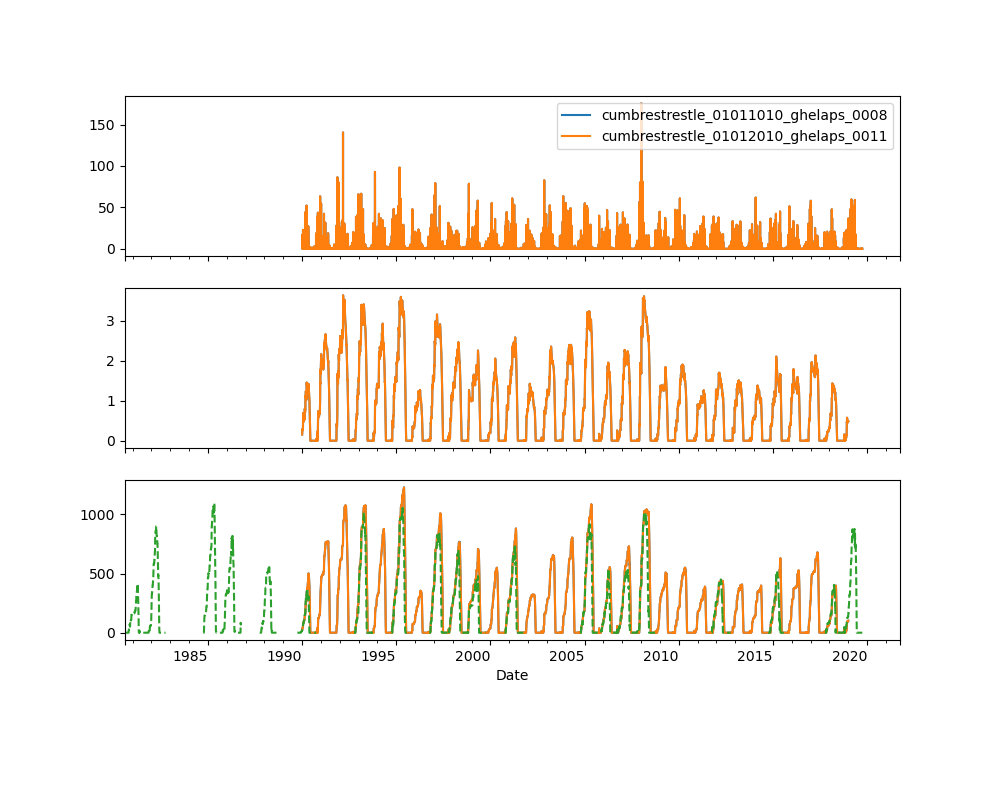

In [11]:
# Plot snow
fig, ax = plt.subplots(3, 1, figsize=(10, 8),sharex=True)

for output in models:
    forcing_snowfall = forcings[output].get_data('Snowf').resample('1D').sum()*3600  #mm
    model_snow = models[output].get_data(['snow','snow_depth'],'land_daily')
    forcing_snowfall.plot(ax=ax[0], label=output)
    model_snow['snow_depth'].plot(ax=ax[1], label=output)
    model_snow['snow'].plot(ax=ax[2], label=output)

# Add on SNOTEL
snotel_data['swe_mm'].plot(ax=ax[2], label='SNOTEL', style='--')
    
ax[0].legend()


In [ ]:
# Plot just showing SWE comparison for 10 years, use in presentations
fig, ax = plt.subplots(figsize=(12, 6))
snotel_data.loc['2005':'2015', 'swe_mm'].plot(ax=ax, label='SNOTEL SWE', color='blue')
model_snow['snow'].loc['2005':'2015'].plot(ax=ax, label='Model SWE', color='red', alpha=0.5)
plt.title(f'SWE Comparison at {site} (2005-2015)', fontsize=16)
ax.set_ylabel('SWE (mm)')
ax.legend()

#### Compare forcings

In [ ]:
compare_Q = pd.DataFrame({names[0]:forcings[names[0]].get_data('Qair'),names[1]:forcings[names[1]].get_data('Qair')})

In [ ]:
compare_T = pd.DataFrame({names[0]:forcings[names[0]].get_data('Tair'),names[1]:forcings[names[1]].get_data('Tair')})

#### RMSE Calculation

In [ ]:
# Shift snotel data index by 12 hours to match model output timing
snotel_data.index = snotel_data.index + pd.Timedelta(hours=12)

In [ ]:
# Combine model and snotel data
combined_df = pd.merge(model_snow, snotel_data[['swe_mm']], left_index=True, right_index=True, how='inner')

In [ ]:
# Calculate the difference between model and snotel SWE
combined_df['swe_diff'] = combined_df['snow'] - combined_df['swe_mm']

In [ ]:
# Calculate the RMSE, don't use first year of data to avoid spinup effects
combined_df = combined_df[combined_df.index >= (combined_df.index.min() + pd.DateOffset(years=1))]
rmse = (combined_df['swe_diff']**2).mean()**0.5
print(f'RMSE between model and SNOTEL SWE: {rmse:.2f} mm')

In [ ]:
# nRMSE
nrmse = rmse / combined_df['swe_mm'].mean()
print(f'mean SNOTEL SWE: {combined_df["swe_mm"].mean():.2f} mm')
print(f'nRMSE = {nrmse}')

### Snow Days Calc

In [ ]:
test = combined_df.loc['2015-10':'2016-07',['snow','swe_mm']]
print(f'SNOTEL: {test.loc[test['swe_mm'] > 5, 'swe_mm'].count()}')
print(f'Model: {test.loc[test['snow'] > 5, 'snow'].count()}')

In [ ]:
#Whole dataset
print(f'SNOTEL: {combined_df.loc[combined_df['swe_mm'] > 5, 'swe_mm'].count()}')
print(f'Model: {combined_df.loc[combined_df['snow'] > 5, 'snow'].count()}')